# AgroMind v2 — Research Notebook: measured improvement over v1

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ravixalgorithm/agromind/blob/main/notebooks/AgroMind_v2_Research.ipynb)

**Project.** AgroMind, crop recommendation for Indian farm conditions.
**Scope.** This notebook holds the raw experimental work behind AgroMind v2. It contains no UI code. Every number in it is computed in the cells below; the headline numbers are also written to `docs/research/results.json` and the figures to `docs/research/figures/`.

**Contents**

0. Setup (Colab-ready)
1. v1 reproduced exactly, its decoding flaw quantified, and v1-fixed
2. Dataset audit: class balance, separability of the Kaggle set, duplicates, cross-source overlap
3. Model comparison on the v2 data (stratified 5-fold CV)
4. Feature ablation (numeric → +soil / +season / +state)
5. Generalisation: leave-one-source-out and leave-states-out
6. Diagnostics: permutation importance, confusion matrix, calibration, McNemar test
7. v3 (real large-scale Indian data) — reserved
8. Summary: v1 → v2

References are given as [n] and resolve to `docs/research/LITERATURE.md`.

## 0. Setup

**Aim.** Make the notebook run unchanged on Google Colab and on a local checkout.
**Method.** If the cell finds the repository (`backend/app/data_loader.py`) next to the notebook it uses it; otherwise it downloads the three CSVs and the four loader modules from the public GitHub repository into `./agromind`. Packages are installed only when missing. Models use scikit-learn [34]. The v2 data are loaded with the application's own `load_dataset()`, so every number below refers to exactly the data the deployed model is trained on.

In [1]:
import importlib.util, subprocess, sys, urllib.request
from pathlib import Path

for pkg in ("xgboost", "lightgbm", "seaborn", "pydantic"):
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)

RAW = "https://raw.githubusercontent.com/ravixalgorithm/agromind/main/"
REPO_FILES = [
    "backend/app/__init__.py", "backend/app/data_loader.py", "backend/app/india_ref.py", "backend/app/schemas.py",
    "backend/data/india_crops.csv", "backend/data/tamilnadu_crops.csv", "backend/data/Crop_recommendation.csv",
]
ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "backend/app/data_loader.py").exists()), None)
if ROOT is None:
    ROOT = Path.cwd() / "agromind"
    for f in REPO_FILES:
        dest = ROOT / f
        dest.parent.mkdir(parents=True, exist_ok=True)
        if not dest.exists():
            urllib.request.urlretrieve(RAW + f, dest)
    print("downloaded from GitHub into", ROOT)
else:
    print("using local checkout", ROOT)

sys.path.insert(0, str(ROOT / "backend"))
OUT = ROOT / "docs/research"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

using local checkout /Users/originkit/.config/baton/worktrees/agromind-334992/claude-1


In [2]:
import json, platform, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, top_k_accuracy_score
from sklearn.model_selection import GroupKFold, StratifiedKFold, cross_val_score, train_test_split
from sklearn.multioutput import MultiOutputClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import shuffle
import xgboost as xgb, lightgbm as lgb

from app.data_loader import NUMERIC, load_dataset

warnings.filterwarnings("ignore")
SEED = 42
T0 = time.time()

# validated categorical palette (fixed order) on a light chart surface
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#b8b7b0"
SRC_COLOR = {"india": PAL[0], "tamilnadu": PAL[1], "kaggle": PAL[2]}
SRC_NAME = {"india": "Multi-state (india)", "tamilnadu": "Tamil Nadu", "kaggle": "Kaggle"}
BLUES = LinearSegmentedColormap.from_list("ramp", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 100, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
})

R = {"figures": []}  # everything that goes to results.json

def save(fig, name, caption):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    R["figures"].append({"file": f"figures/{name}", "caption": caption})
    plt.show()

def r4(x):
    return round(float(x), 4)

def ms(a):
    return f"{np.mean(a):.4f} ± {np.std(a):.4f}"

def pct(a):
    return f"{100 * np.mean(a):.2f}% ± {100 * np.std(a):.2f}%"

def folds_pct(a):
    return "[" + ", ".join(f"{100 * v:.2f}" for v in a) + "] %"

print("python", platform.python_version(), "| sklearn", sklearn.__version__, "| xgboost", xgb.__version__,
      "| lightgbm", lgb.__version__, "| pandas", pd.__version__)

python 3.12.14 | sklearn 1.9.1 | xgboost 3.4.1 | lightgbm 4.7.0 | pandas 3.1.1


## 1. v1: reproduction, the decoding flaw, and v1-fixed

### 1.1 Exact reproduction of v1

**Aim.** Re-run the previous version (`notebooks/Crop_Recommendation_Testing_Final.ipynb`) line for line, so that every later comparison starts from v1's own numbers.
**Method.** As in v1: the Kaggle *Crop Recommendation* set [31] (2,200 rows, 22 crops, 7 numeric features), shuffled with `random_state=5`, targets one-hot encoded with `pd.get_dummies`, one 75/25 split (`random_state=0`), and each classifier wrapped in `MultiOutputClassifier`, so that 22 independent binary "is it crop *c*?" heads are trained. As in v1, a prediction is decoded with `argmax` over the 22 boolean outputs. v1's GridSearch-tuned forest is not re-run: v1 itself reports that it equals the default forest (0.9800).

In [3]:
kag = pd.read_csv(ROOT / "backend/data/Crop_recommendation.csv").rename(columns={"label": "Crop"})
FEATS = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
d1 = shuffle(kag, random_state=5)
x, y_dummy = d1[FEATS], pd.get_dummies(d1["Crop"])
x_train, x_test, y_train, y_test = train_test_split(x, y_dummy, test_size=0.25, random_state=0)
CLASS0 = y_dummy.columns[0]
print("columns of the one-hot target start with:", list(y_dummy.columns[:3]), "-> class 0 =", CLASS0)

def v1_models():
    return {"GaussianNB": GaussianNB(), "DecisionTree": DecisionTreeClassifier(random_state=6),
            "RandomForest": RandomForestClassifier(random_state=1), "KNN": KNeighborsClassifier(),
            "GradientBoosting": GradientBoostingClassifier()}

V1_REPORTED = {"GaussianNB": 0.9709, "DecisionTree": 0.9673, "RandomForest": 0.9800, "KNN": 0.9745, "GradientBoosting": 0.9800}
true_idx = y_test.values.argmax(1)
rows, v1_fired = [], {}
for name, est in v1_models().items():
    P = MultiOutputClassifier(est, n_jobs=-1).fit(x_train, y_train).predict(x_test).astype(bool)
    fired, pred_idx = P.sum(1), P.argmax(1)
    v1_fired[name] = (fired, pred_idx)
    rows.append({
        "model": name,
        "reported_acc (v1 notebook)": V1_REPORTED[name],
        "reproduced_acc (argmax decode)": accuracy_score(true_idx, pred_idx),
        "exact_match_acc": accuracy_score(y_test.values, P),
        "zero_heads_fire_%": 100 * (fired == 0).mean(),
        "multiple_heads_fire_%": 100 * (fired > 1).mean(),
        f"predicted_{CLASS0}_%": 100 * (pred_idx == 0).mean(),
        f"true_{CLASS0}_%": 100 * (true_idx == 0).mean(),
        f"zero_fire_rows_scored_correct_as_{CLASS0}": int(((fired == 0) & (true_idx == 0)).sum()),
    })
v1_tab = pd.DataFrame(rows).set_index("model")
for name, r in v1_tab.iterrows():
    print(f"{name:17s} Accuracy (v1 argmax decode): {100 * r['reproduced_acc (argmax decode)']:.2f}%   "
          f"[v1 notebook reported {100 * r['reported_acc (v1 notebook)']:.2f}%]   "
          f"rows with no head firing: {r['zero_heads_fire_%']:.2f}%")
v1_tab.round(4)

columns of the one-hot target start with: ['apple', 'banana', 'blackgram'] -> class 0 = apple


GaussianNB        Accuracy (v1 argmax decode): 97.09%   [v1 notebook reported 97.09%]   rows with no head firing: 0.00%
DecisionTree      Accuracy (v1 argmax decode): 96.73%   [v1 notebook reported 96.73%]   rows with no head firing: 3.09%
RandomForest      Accuracy (v1 argmax decode): 98.00%   [v1 notebook reported 98.00%]   rows with no head firing: 1.82%
KNN               Accuracy (v1 argmax decode): 97.45%   [v1 notebook reported 97.45%]   rows with no head firing: 0.18%
GradientBoosting  Accuracy (v1 argmax decode): 98.00%   [v1 notebook reported 98.00%]   rows with no head firing: 1.64%


,reported_acc (v1 notebook),reproduced_acc (argmax decode),exact_match_acc,zero_heads_fire_%,multiple_heads_fire_%,predicted_apple_%,true_apple_%,zero_fire_rows_scored_correct_as_apple
model,,,,,,,,
GaussianNB,0.9709,0.9709,0.8691,0.0000,13.0909,5.0909,5.0909,0
DecisionTree,0.9673,0.9673,0.9455,3.0909,2.3636,8.1818,5.0909,0
RandomForest,0.9800,0.9800,0.9800,1.8182,0.0000,6.9091,5.0909,0
KNN,0.9745,0.9745,0.9745,0.1818,0.0000,5.2727,5.0909,0
GradientBoosting,0.9800,0.9800,0.9745,1.6364,0.5455,6.7273,5.0909,0


In [4]:
fired, pred_idx = v1_fired["RandomForest"]
print("v1 RandomForest, argmax decode — confusion matrix (rows = true, columns = predicted, column 0 = apple)")
print(confusion_matrix(true_idx, pred_idx))
print(classification_report(true_idx, pred_idx, target_names=list(y_dummy.columns), digits=4, zero_division=0))

v1 RandomForest, argmax decode — confusion matrix (rows = true, columns = predicted, column 0 = apple)
[[28  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 19  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 4  0 18  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0 31  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 30  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 23  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 26  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 21  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 1  0  0  0  0  0  0  0 25  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 25  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 23  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0 19  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0 29  0  0  0  0  0  0  0  0  0]


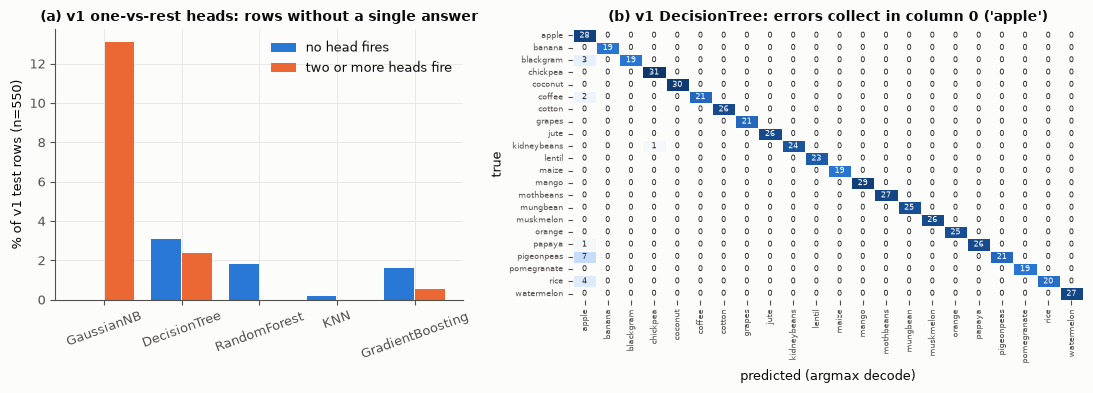

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
pos = np.arange(len(v1_tab))
ax.bar(pos - 0.2, v1_tab["zero_heads_fire_%"], 0.38, color=PAL[0], label="no head fires")
ax.bar(pos + 0.2, v1_tab["multiple_heads_fire_%"], 0.38, color=PAL[1], label="two or more heads fire")
ax.set_xticks(pos, v1_tab.index, rotation=20)
ax.set_ylabel("% of v1 test rows (n=550)")
ax.set_title("(a) v1 one-vs-rest heads: rows without a single answer")
ax.legend(frameon=False)
worst = v1_tab["zero_heads_fire_%"].idxmax()
cm = confusion_matrix(true_idx, v1_fired[worst][1], labels=range(len(y_dummy.columns)))
sns.heatmap(cm, ax=axes[1], cmap=BLUES, cbar=False, xticklabels=y_dummy.columns, yticklabels=y_dummy.columns,
            linewidths=0.4, linecolor="#fcfcfb", annot=cm, fmt="d", annot_kws={"fontsize": 6})
axes[1].set_xlabel("predicted (argmax decode)"); axes[1].set_ylabel("true")
axes[1].set_title(f"(b) v1 {worst}: errors collect in column 0 ('{CLASS0}')")
axes[1].tick_params(labelsize=6)
fig.tight_layout()
save(fig, "01_v1_decode_flaw.png", "v1 MultiOutputClassifier decode: share of test rows where zero or several one-vs-rest heads fire, and the argmax confusion matrix showing errors falling into class 0 (apple).")

**Observation.** The reproduction is exact for four of the five models (GaussianNB 97.09 %, DecisionTree 96.73 %, RandomForest 98.00 %, KNN 97.45 %). GradientBoosting gives 98.18 % against v1's 98.00 %, a one-row difference that we attribute to the scikit-learn version. The decoding, however, is unsound:

* Up to **3.09 %** of test rows (DecisionTree) receive *no* positive head at all, and up to **13.09 %** (GaussianNB) receive *two or more*. In both cases `argmax` silently returns an answer: the first column (`apple`) when no head fires, and the alphabetically first firing crop otherwise.
* These rows pile into column 0. DecisionTree predicts `apple` for 8.18 % of rows although only 5.09 % are apple, and v1's RandomForest has `apple` precision of only 0.737 (classification report above).
* Scored as a strict one-of-22 decision (exact match), GaussianNB falls from the reported 97.09 % to **86.91 %**, and DecisionTree to 94.55 %.
* In this split no row with zero heads firing happened to be a true apple, so the flaw *lowered* v1's accuracy rather than inflating it. It is nonetheless a methodological error: the reported number does not measure the decision the system makes.

### 1.2 v1-fixed: the same data and split, as a proper multiclass problem

**Aim.** Separate the effect of the decoding flaw from the effect of the data.
**Method.** The same five estimators are trained directly on the crop label (a single multiclass model, so each row receives exactly one prediction). They are scored on the identical 75/25 split and, because a single 550-row split is noisy, also by stratified 5-fold cross-validation on the full Kaggle set (mean ± standard deviation over folds).

In [6]:
y_lab = d1["Crop"]
xl_train, xl_test, yl_train, yl_test = train_test_split(x, y_lab, test_size=0.25, random_state=0)
assert (xl_test.index == x_test.index).all()  # identical rows to v1's split
skf_k = StratifiedKFold(5, shuffle=True, random_state=SEED)
rows = []
for name, est in v1_models().items():
    pred = est.fit(xl_train, yl_train).predict(xl_test)
    cv = cross_val_score(v1_models()[name], kag[FEATS], kag["Crop"], cv=skf_k, scoring="accuracy", n_jobs=-1)
    print(f"{name:17s} v1-fixed Accuracy (same split): {100 * accuracy_score(yl_test, pred):.2f}%   "
          f"5-fold CV: {folds_pct(cv)} -> {pct(cv)}")
    if name == "RandomForest":
        rf_fixed_report = classification_report(yl_test, pred, digits=4)
    rows.append({"model": name, "v1_reported": V1_REPORTED[name],
                 "v1_reproduced": v1_tab.loc[name, "reproduced_acc (argmax decode)"],
                 "v1_exact_match": v1_tab.loc[name, "exact_match_acc"],
                 "v1_fixed_same_split": accuracy_score(yl_test, pred),
                 "v1_fixed_macro_f1": f1_score(yl_test, pred, average="macro"),
                 "v1_fixed_cv5_mean": cv.mean(), "v1_fixed_cv5_std": cv.std()})
v1f_tab = pd.DataFrame(rows).set_index("model")
R["v1"] = {m: {"reported_accuracy": r4(r["reported_acc (v1 notebook)"]),
               "reproduced_accuracy": r4(r["reproduced_acc (argmax decode)"]),
               "exact_match_accuracy": r4(r["exact_match_acc"]),
               "zero_fire_pct": round(r["zero_heads_fire_%"], 2), "multi_fire_pct": round(r["multiple_heads_fire_%"], 2),
               "pred_class0_pct": round(r[f"predicted_{CLASS0}_%"], 2), "true_class0_pct": round(r[f"true_{CLASS0}_%"], 2)}
           for m, r in v1_tab.iterrows()}
R["v1_fixed"] = {m: {"accuracy_same_split": r4(r.v1_fixed_same_split), "macro_f1_same_split": r4(r.v1_fixed_macro_f1),
                     "cv5_accuracy_mean": r4(r.v1_fixed_cv5_mean), "cv5_accuracy_std": r4(r.v1_fixed_cv5_std)}
                 for m, r in v1f_tab.iterrows()}
print("\nv1-fixed RandomForest — classification report (same 550 test rows as v1)")
print(rf_fixed_report)
v1f_tab.round(4)

GaussianNB        v1-fixed Accuracy (same split): 99.27%   5-fold CV: [99.32, 99.55, 99.77, 99.32, 99.32] % -> 99.45% ± 0.18%
DecisionTree      v1-fixed Accuracy (same split): 98.73%   5-fold CV: [97.95, 99.32, 99.32, 98.41, 99.32] % -> 98.86% ± 0.57%


RandomForest      v1-fixed Accuracy (same split): 99.45%   5-fold CV: [99.55, 99.32, 100.00, 99.55, 99.09] % -> 99.50% ± 0.30%
KNN               v1-fixed Accuracy (same split): 97.45%   5-fold CV: [98.41, 98.18, 97.50, 97.27, 99.09] % -> 98.09% ± 0.65%


GradientBoosting  v1-fixed Accuracy (same split): 98.91%   5-fold CV: [98.86, 98.41, 99.77, 99.09, 99.32] % -> 99.09% ± 0.45%

v1-fixed RandomForest — classification report (same 550 test rows as v1)
              precision    recall  f1-score   support

       apple     1.0000    1.0000    1.0000        28
      banana     1.0000    1.0000    1.0000        19
   blackgram     1.0000    0.9545    0.9767        22
    chickpea     1.0000    1.0000    1.0000        31
     coconut     1.0000    1.0000    1.0000        30
      coffee     1.0000    1.0000    1.0000        23
      cotton     1.0000    1.0000    1.0000        26
      grapes     1.0000    1.0000    1.0000        21
        jute     0.9615    0.9615    0.9615        26
 kidneybeans     1.0000    1.0000    1.0000        25
      lentil     1.0000    1.0000    1.0000        23
       maize     0.9500    1.0000    0.9744        19
       mango     1.0000    1.0000    1.0000        29
   mothbeans     1.0000    1.0000    1.0000

,v1_reported,v1_reproduced,v1_exact_match,v1_fixed_same_split,v1_fixed_macro_f1,v1_fixed_cv5_mean,v1_fixed_cv5_std
model,,,,,,,
GaussianNB,0.9709,0.9709,0.8691,0.9927,0.9927,0.9945,0.0018
DecisionTree,0.9673,0.9673,0.9455,0.9873,0.9867,0.9886,0.0057
RandomForest,0.9800,0.9800,0.9800,0.9945,0.9941,0.9950,0.0030
KNN,0.9745,0.9745,0.9745,0.9745,0.9742,0.9809,0.0065
GradientBoosting,0.9800,0.9800,0.9745,0.9891,0.9885,0.9909,0.0045


**Observation.** Treated correctly as a multiclass problem, the same estimators on the same rows score higher than v1 reported: RandomForest 99.45 % (5-fold CV **99.50 % ± 0.30 %**), GaussianNB 99.27 % (CV 99.45 % ± 0.18 %). v1-fixed is therefore the fair baseline. It shows that the Kaggle task is close to saturated, which is consistent with the 99 %+ figures reported on this dataset in the literature [8, 11, 12]. §2.1 shows why such numbers carry little information.

## 2. Dataset audit

**Aim.** Establish what the v2 training data actually contain before any model is compared, and explain why near-perfect accuracy on the Kaggle set is weak evidence.
**Method.** The three sources are merged with the application's `load_dataset()`. We report per-source size and vocabulary, class balance, a box-rule separability test, exact duplicates, and cross-source agreement for crops that occur in several sources.

In [7]:
df = load_dataset()
CAT = ["soil", "season", "state"]
FEATURES = NUMERIC + CAT
src_tab = df.groupby("source").agg(rows=("crop", "size"), crops=("crop", "nunique"), states=("state", "nunique"),
                                   soils=("soil", "nunique"), seasons=("season", "nunique"))
src_tab.loc["merged (v2)"] = [len(df), df.crop.nunique(), df.state.nunique(), df.soil.nunique(), df.season.nunique()]
counts = df.crop.value_counts()
print(f"{len(df):,} rows, {df.crop.nunique()} crops; rows per crop: min {counts.min()} ({counts.idxmin()}), "
      f"median {int(counts.median())}, max {counts.max()} ({counts.idxmax()}); imbalance ratio {counts.max() / counts.min():.1f}:1")
R["dataset"] = {"rows": int(len(df)), "crops": int(df.crop.nunique()),
                "rows_by_source": df.source.value_counts().to_dict(),
                "crops_by_source": df.groupby("source").crop.nunique().to_dict(),
                "rows_per_crop_min": int(counts.min()), "rows_per_crop_median": int(counts.median()),
                "rows_per_crop_max": int(counts.max()), "imbalance_ratio": round(counts.max() / counts.min(), 1)}
src_tab

67,200 rows, 74 crops; rows per crop: min 54 (barley), median 1000, max 2000 (cowpea); imbalance ratio 37.0:1


,rows,crops,states,soils,seasons
source,,,,,
india,8000,25,16,7,3
kaggle,2200,22,1,1,3
tamilnadu,57000,55,1,10,3
merged (v2),67200,74,17,10,3


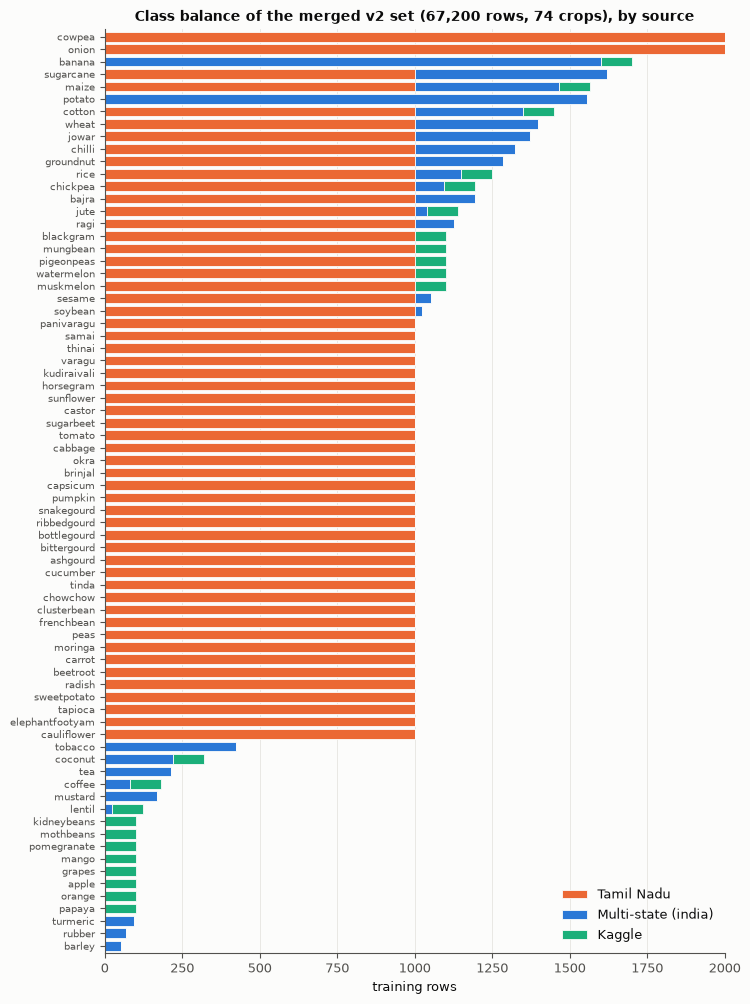

In [8]:
by = df.groupby(["crop", "source"]).size().unstack(fill_value=0).loc[counts.index[::-1]]
fig, ax = plt.subplots(figsize=(8, 12))
left = np.zeros(len(by))
for s in ["tamilnadu", "india", "kaggle"]:
    ax.barh(by.index, by[s], left=left, color=SRC_COLOR[s], label=SRC_NAME[s], height=0.78, edgecolor="#fcfcfb", linewidth=0.6)
    left += by[s].values
ax.set_xlabel("training rows"); ax.set_ylim(-0.6, len(by) - 0.4)
ax.tick_params(axis="y", labelsize=7); ax.grid(axis="y", visible=False)
ax.set_title(f"Class balance of the merged v2 set ({len(df):,} rows, {df.crop.nunique()} crops), by source")
ax.legend(frameon=False, loc="lower right")
save(fig, "02_class_balance.png", "Rows per crop in the merged v2 training set, stacked by source.")

### 2.1 Why ~99 % on the Kaggle set is not impressive

**Method.** For every crop we take the per-feature minimum and maximum over the *training* rows, which gives one axis-aligned box per crop in the 7-dimensional numeric space. A test row is then checked against every box. If most test rows fall inside exactly one box, a lookup table of 22 boxes already classifies the data and accuracy near 100 % says little about the learner. We also report the *relative within-crop spread*: the standard deviation of a feature inside one crop divided by its standard deviation over the whole source, averaged over crops and features (1.0 = a crop is as spread out as the whole data; small = tight, separable clusters).

In [9]:
def box_test(X_tr, y_tr, X_te, y_te):
    g = pd.DataFrame(X_tr).groupby(np.asarray(y_tr))
    lo, hi = g.min(), g.max()
    Xa = np.asarray(X_te, dtype=float)
    inside = ((Xa[:, None, :] >= lo.values[None]) & (Xa[:, None, :] <= hi.values[None])).all(2)
    n_in = inside.sum(1)
    one = n_in == 1
    correct = one & (lo.index.values[inside.argmax(1)] == np.asarray(y_te))
    return {"rows_in_exactly_one_box_%": 100 * one.mean(), "rows_in_no_box_%": 100 * (n_in == 0).mean(),
            "rows_in_2plus_boxes_%": 100 * (n_in > 1).mean(), "box_rule_accuracy": correct.mean()}

def within_spread(d, cols, label):
    overall = d[cols].std()
    return float((d.groupby(label)[cols].std() / overall).mean().mean())

sep = {"Kaggle (v1 data)": box_test(xl_train, yl_train, xl_test, yl_test)}
tr, te = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df.crop)
for s in ["india", "tamilnadu"]:
    a, b = tr[tr.source == s], te[te.source == s]
    sep[SRC_NAME[s]] = box_test(a[NUMERIC], a.crop, b[NUMERIC], b.crop)
sep["merged v2"] = box_test(tr[NUMERIC], tr.crop, te[NUMERIC], te.crop)
sep_tab = pd.DataFrame(sep).T
sep_tab["within_crop_spread"] = [within_spread(kag, FEATS, "Crop")] + \
    [within_spread(df[df.source == s], NUMERIC, "crop") for s in ["india", "tamilnadu"]] + [within_spread(df, NUMERIC, "crop")]
R["dataset"]["separability"] = {k: {c: r4(v) for c, v in row.items()} for k, row in sep_tab.iterrows()}
sep_tab.round(4)

,rows_in_exactly_one_box_%,rows_in_no_box_%,rows_in_2plus_boxes_%,box_rule_accuracy,within_crop_spread
Kaggle (v1 data),88.1818,11.4545,0.3636,0.8800,0.3190
Multi-state (india),0.1882,0.6274,99.1844,0.0006,0.8701
Tamil Nadu,72.6197,0.4208,26.9595,0.7251,0.3632
merged v2,5.0744,0.1786,94.7470,0.0500,0.5169


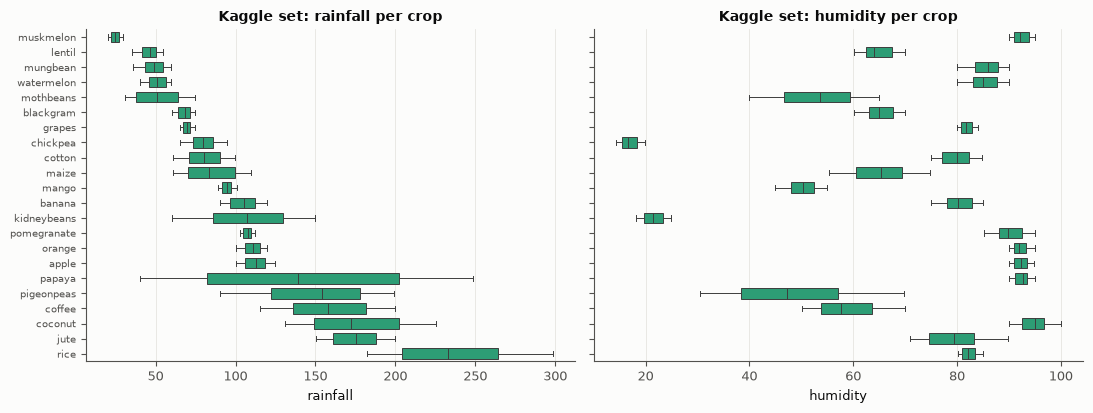

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
order = kag.groupby("Crop")["rainfall"].median().sort_values().index
for ax, col in zip(axes, ["rainfall", "humidity"]):
    sns.boxplot(data=kag, y="Crop", x=col, order=order, ax=ax, color=PAL[2], linewidth=0.7, fliersize=1.5, width=0.7)
    ax.set_title(f"Kaggle set: {col} per crop"); ax.set_ylabel(""); ax.tick_params(axis="y", labelsize=7)
fig.tight_layout()
save(fig, "03_kaggle_narrow_boxes.png", "Per-crop distributions of rainfall and humidity in the Kaggle set: narrow, largely non-overlapping ranges make the task almost a lookup.")

**Observation.** On the Kaggle set, **88.2 %** of test rows fall inside exactly one crop's min–max box. That 22-row lookup table alone reaches **88.0 %** accuracy, with no learning at all. The within-crop spread is 0.32, meaning each crop is a tight, isolated cluster (figure above). The multi-state source is the opposite: 99.2 % of its rows lie in two or more boxes, and its within-crop spread is 0.87, so crops overlap almost completely in the numeric space. The Tamil Nadu source sits close to the Kaggle profile (72.6 % of rows in exactly one box, spread 0.36). The high accuracy on the Kaggle and Tamil Nadu rows is therefore largely a property of the data; the multi-state rows are where model quality actually shows (§3).

### 2.2 Duplicates and conflicting labels

In [11]:
dup = {}
for name, d in [("kaggle", df[df.source == "kaggle"]), ("india", df[df.source == "india"]),
                ("tamilnadu", df[df.source == "tamilnadu"]), ("merged", df)]:
    full_dup = d.duplicated(FEATURES + ["crop"]).sum()
    feat = d.groupby(FEATURES, dropna=False).crop.nunique()
    num_feat = d.groupby(NUMERIC).crop.nunique()
    dup[name] = {"rows": len(d), "exact_duplicate_rows": int(full_dup),
                 "feature_vectors_with_conflicting_labels": int((feat > 1).sum()),
                 "numeric_vectors_with_conflicting_labels": int((num_feat > 1).sum())}
R["dataset"]["duplicates"] = dup
pd.DataFrame(dup).T

,rows,exact_duplicate_rows,feature_vectors_with_conflicting_labels,numeric_vectors_with_conflicting_labels
kaggle,2200,0,0,0
india,8000,0,0,0
tamilnadu,57000,0,0,0
merged,67200,0,0,0


### 2.3 Cross-source overlap: do the sources agree about the same crop?

**Method.** We count the crops shared between each pair of sources and, for the crops present in all three, compare per-source medians of each numeric feature. If the sources described the same physical quantity in the same way, these medians would be close.

In [12]:
SRCS = ["india", "tamilnadu", "kaggle"]
vocab = {s: set(df.loc[df.source == s, "crop"]) for s in SRCS}
overlap = pd.DataFrame([[len(vocab[a] & vocab[b]) for b in SRCS] for a in SRCS],
                       index=[SRC_NAME[s] for s in SRCS], columns=[SRC_NAME[s] for s in SRCS])
shared_all = sorted(vocab["india"] & vocab["tamilnadu"] & vocab["kaggle"])
print("crops present in all three sources:", shared_all)
print("crops present in only one source:", sum(1 for c in set(df.crop) if sum(c in vocab[s] for s in SRCS) == 1))
med = df[df.crop.isin(shared_all)].groupby(["crop", "source"])[NUMERIC].median().round(1)
R["dataset"]["crop_overlap"] = {f"{a}&{b}": len(vocab[a] & vocab[b]) for i, a in enumerate(SRCS) for b in SRCS[i + 1:]}
R["dataset"]["shared_by_all_sources"] = shared_all
R["dataset"]["rainfall_median_by_source"] = df.groupby("source").rainfall.median().round(1).to_dict()
display(overlap)
med

crops present in all three sources: ['chickpea', 'cotton', 'jute', 'maize', 'rice']
crops present in only one source: 51


,Multi-state (india),Tamil Nadu,Kaggle
Multi-state (india),25,14,9
Tamil Nadu,14,55,10
Kaggle,9,10,22


N     P      K   ph  temperature  humidity  rainfall
crop     source                                                             
chickpea india      153.6  13.4  124.8  7.3         26.9      47.9    1017.0
         kaggle      39.0  68.0   79.0  7.4         18.9      16.7      79.7
         tamilnadu   50.4  29.3   29.8  6.3         24.7      60.0     825.6
cotton   india      156.6  17.4  158.0  7.2         32.5      55.0     867.0
         kaggle     117.0  46.0   19.0  6.8         24.0      80.0      80.2
         tamilnadu   99.2  50.4   50.3  7.5         25.3      80.0    1001.9
jute     india      179.8  18.9  165.1  6.8         32.0      77.4    1802.1
         kaggle      78.0  46.0   40.0  6.7         25.0      79.5     175.6
         tamilnadu   78.7  39.8   40.0  6.8         31.0      79.8    1144.2
maize    india      117.3  13.3  136.6  6.8         25.2      59.9     990.4
         kaggle      76.0  48.5   20.0  6.3         22.8      65.3      83.5
         tamilnadu  150.3  74.6   75.4  6.2         22.5      72.6     651.8
rice     india      190.0  18.8  162.0  7.0         24.6      70.8    1498.9
         kaggle      80.0  47.0   40.0  6.4         23.7      82.2     233.1
         tamilnadu   89.7  49.8   50.0  6.4         30.0      69.8    1705.4

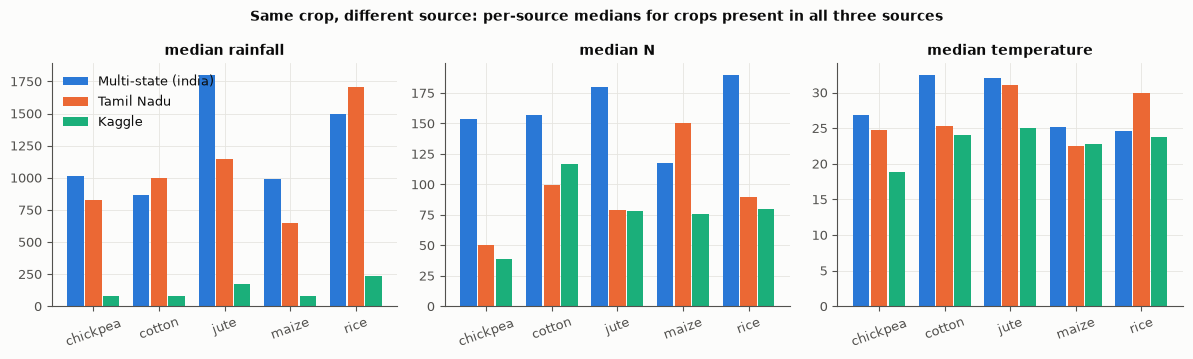

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col in zip(axes, ["rainfall", "N", "temperature"]):
    m = med[col].unstack()[SRCS]
    pos = np.arange(len(m))
    for i, s in enumerate(SRCS):
        ax.bar(pos + (i - 1) * 0.27, m[s], 0.25, color=SRC_COLOR[s], label=SRC_NAME[s])
    ax.set_xticks(pos, m.index, rotation=20); ax.set_title(f"median {col}")
axes[0].legend(frameon=False)
fig.suptitle("Same crop, different source: per-source medians for crops present in all three sources", fontsize=10, fontweight="bold")
fig.tight_layout()
save(fig, "04_cross_source_shift.png", "Per-source medians of rainfall, N and temperature for the crops shared by all three sources.")

In [14]:
st = pd.crosstab(df.state, df.source)
print("state value  -> rows per source")
print(st.loc[["Tamil Nadu", "Unspecified"]])
R["dataset"]["state_source_confound"] = {
    "Unspecified_is_kaggle_pct": round(100 * st.loc["Unspecified", "kaggle"] / st.loc["Unspecified"].sum(), 2),
    "TamilNadu_rows_from_tamilnadu_source_pct": round(100 * st.loc["Tamil Nadu", "tamilnadu"] / st.loc["Tamil Nadu"].sum(), 2)}

state value  -> rows per source
source       india  kaggle  tamilnadu
state                                
Tamil Nadu     462       0      57000
Unspecified      0    2200          0


**Observation.**

* **No duplicates.** There are no exact duplicate rows and no identical feature vectors with conflicting labels, in any source or in the merge.
* **Little crop overlap.** The sources share few crops: only **5 crops** (chickpea, cotton, jute, maize, rice) occur in all three, and **51 of the 74** occur in only one source.
* **The same column means different things.** For a shared crop the sources disagree strongly. Median `rainfall` for rice is 233 mm in Kaggle, 1,499 mm in the multi-state set and 1,705 mm in Tamil Nadu, and chickpea's median N is 39 (Kaggle) against 154 (multi-state). The `rainfall` column is not one physical quantity: the Tamil Nadu value is the crop's *water requirement* (`WATERREQUIRED`), and the multi-state value is a seasonal total.
* **`state` largely encodes the source.** `Unspecified` is 100 % Kaggle, and 99.2 % of `Tamil Nadu` rows come from the Tamil Nadu source.

These facts predict the generalisation results of §5.

## 3. Model comparison on the v2 data

**Aim.** Decide, with a protocol that has error bars, which learner suits the merged data, and check whether the deployed Random Forest [21] is a reasonable choice.
**Method.** Features are the seven numerics plus one-hot `soil`, `season` and `state`, exactly as in the application (`model_service.py`). Evaluation is stratified 5-fold cross-validation with fixed folds shared by every model; we report accuracy, macro-F1 (each crop weighted equally, so small classes count), top-3 accuracy (the UI shows three recommendations) and mean fit time per fold. Distance-based and linear models get standardised numerics. **Computational budget.** The RBF-SVM and the two gradient-boosting libraries (XGBoost [22], LightGBM [35]) are trained on a stratified 15,000-row subsample of each training fold and scored on the full test fold, to keep the notebook near 10 minutes on a CPU. A Random Forest trained on the same 15k subsample is included as a like-for-like control, so the boosters can be compared with the forest at equal data. A multiclass booster builds one tree per class per round (74 × 200 = 14,800 trees per fit), which is why it is the expensive model here. In pilot runs, both histogram boosters (scikit-learn's HistGradientBoosting and LightGBM) diverged at learning rate 0.1 on 74 classes (accuracy 0.23 and 0.09). LightGBM therefore uses 0.05 with L2 regularisation. HistGradientBoosting is omitted: it took over 2 minutes per 15k-row fit on our CPU, and LightGBM represents the same histogram-GBDT family.

In [15]:
le = LabelEncoder().fit(df.crop)
Y, X = le.transform(df.crop), df[FEATURES]
K = len(le.classes_)
FOLDS = list(StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, Y))
SUB = 15_000

def prep(num=NUMERIC, cat=CAT, scale=False):
    parts = [("num", StandardScaler() if scale else "passthrough", list(num))]
    if cat:
        parts.insert(0, ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat)))
    return ColumnTransformer(parts)

def rf_v2():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1)

MODELS = {  # name: (estimator factory, scale numerics, training-row cap)
    "LogisticRegression": (lambda: LogisticRegression(max_iter=2000), True, None),
    "KNN (k=5)": (lambda: KNeighborsClassifier(n_jobs=-1), True, None),
    "GaussianNB": (GaussianNB, False, None),
    "DecisionTree": (lambda: DecisionTreeClassifier(random_state=SEED), False, None),
    "SVM-RBF (15k)": (lambda: SVC(C=10, gamma="scale", random_state=SEED), True, SUB),
    "RandomForest (15k)": (rf_v2, False, SUB),
    "RandomForest (v2 deployed)": (rf_v2, False, None),
    "ExtraTrees": (lambda: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1), False, None),
    "LightGBM (15k)": (lambda: lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, reg_lambda=1.0, verbose=-1,
                                                   random_state=SEED, n_jobs=4), False, SUB),
    "XGBoost (15k)": (lambda: xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1, tree_method="hist",
                                                random_state=SEED, n_jobs=4), False, SUB),
}

def cap(idx, n):
    return idx if n is None or n >= len(idx) else train_test_split(idx, train_size=n, stratify=Y[idx], random_state=SEED)[0]

def scores_of(model, Xt):
    return model.predict_proba(Xt) if hasattr(model, "predict_proba") else model.decision_function(Xt)

def run_cv(make, num=NUMERIC, cat=CAT, scale=False, n=None, folds=FOLDS):
    out = {"acc": [], "f1": [], "top3": [], "fit_s": []}
    oof = np.empty(len(Y), dtype=int)
    for tr_i, te_i in folds:
        tr_i = cap(tr_i, n)
        model = make_pipeline(prep(num, cat, scale), make())
        t = time.time(); model.fit(X.iloc[tr_i], Y[tr_i]); out["fit_s"].append(time.time() - t)
        S = scores_of(model, X.iloc[te_i]); pred = model.classes_[S.argmax(1)]
        oof[te_i] = pred
        out["acc"].append(accuracy_score(Y[te_i], pred)); out["f1"].append(f1_score(Y[te_i], pred, average="macro"))
        out["top3"].append(top_k_accuracy_score(Y[te_i], S, k=3, labels=model.classes_))
    return out, oof

cv_res, OOF = {}, {}
for name, (make, scale, n) in MODELS.items():
    cv_res[name], OOF[name] = run_cv(make, scale=scale, n=n)
    r = cv_res[name]
    print(f"{name}\n  accuracy per fold {folds_pct(r['acc'])}\n  Accuracy {pct(r['acc'])} | macro-F1 {pct(r['f1'])} | "
          f"top-3 {pct(r['top3'])} | fit {np.mean(r['fit_s']):.1f}s/fold | elapsed {time.time() - T0:.0f}s", flush=True)

LogisticRegression
  accuracy per fold [87.22, 86.96, 87.40, 86.95, 86.60] %
  Accuracy 87.03% ± 0.27% | macro-F1 84.60% ± 0.34% | top-3 97.76% ± 0.19% | fit 14.3s/fold | elapsed 116s


KNN (k=5)
  accuracy per fold [89.23, 88.91, 89.02, 89.00, 88.88] %
  Accuracy 89.01% ± 0.12% | macro-F1 86.87% ± 0.26% | top-3 96.72% ± 0.10% | fit 0.1s/fold | elapsed 124s


GaussianNB
  accuracy per fold [72.15, 71.62, 71.30, 71.40, 71.32] %
  Accuracy 71.56% ± 0.32% | macro-F1 70.24% ± 0.39% | top-3 87.65% ± 0.29% | fit 0.1s/fold | elapsed 126s


DecisionTree
  accuracy per fold [91.95, 91.75, 92.34, 92.36, 92.11] %
  Accuracy 92.10% ± 0.23% | macro-F1 89.27% ± 0.21% | top-3 92.34% ± 0.24% | fit 0.9s/fold | elapsed 131s


SVM-RBF (15k)
  accuracy per fold [90.86, 90.60, 91.05, 90.92, 90.56] %
  Accuracy 90.80% ± 0.19% | macro-F1 88.20% ± 0.17% | top-3 98.26% ± 0.10% | fit 7.1s/fold | elapsed 517s


RandomForest (15k)
  accuracy per fold [93.44, 93.24, 93.68, 93.57, 93.35] %
  Accuracy 93.46% ± 0.16% | macro-F1 90.76% ± 0.30% | top-3 98.75% ± 0.06% | fit 1.2s/fold | elapsed 525s


RandomForest (v2 deployed)
  accuracy per fold [94.28, 94.18, 94.52, 94.39, 94.28] %
  Accuracy 94.33% ± 0.12% | macro-F1 92.15% ± 0.29% | top-3 99.18% ± 0.09% | fit 4.6s/fold | elapsed 551s


ExtraTrees
  accuracy per fold [92.98, 93.20, 93.21, 93.16, 92.97] %
  Accuracy 93.10% ± 0.11% | macro-F1 91.08% ± 0.17% | top-3 98.99% ± 0.03% | fit 2.7s/fold | elapsed 568s


LightGBM (15k)
  accuracy per fold [93.56, 93.41, 93.71, 93.40, 93.33] %
  Accuracy 93.48% ± 0.14% | macro-F1 90.96% ± 0.46% | top-3 98.83% ± 0.10% | fit 90.1s/fold | elapsed 1064s


XGBoost (15k)
  accuracy per fold [93.47, 93.24, 93.74, 93.44, 93.30] %
  Accuracy 93.44% ± 0.17% | macro-F1 90.94% ± 0.55% | top-3 98.83% ± 0.07% | fit 54.1s/fold | elapsed 1340s


In [16]:
SRC = df.source.values
cmp_tab = pd.DataFrame({name: {"accuracy": ms(r["acc"]), "macro_f1": ms(r["f1"]), "top3": ms(r["top3"]),
                               "fit_s_per_fold": round(np.mean(r["fit_s"]), 2),
                               **{f"acc_{s}": round(float((OOF[name][SRC == s] == Y[SRC == s]).mean()), 4) for s in SRCS}}
                        for name, r in cv_res.items()}).T.sort_values("macro_f1", ascending=False)
R["models"] = {name: {"accuracy_mean": r4(np.mean(r["acc"])), "accuracy_std": r4(np.std(r["acc"])),
                      "macro_f1_mean": r4(np.mean(r["f1"])), "macro_f1_std": r4(np.std(r["f1"])),
                      "top3_mean": r4(np.mean(r["top3"])), "top3_std": r4(np.std(r["top3"])),
                      "fit_seconds_per_fold": round(float(np.mean(r["fit_s"])), 2),
                      "train_rows_cap": MODELS[name][2],
                      **{f"oof_accuracy_{s}": r4((OOF[name][SRC == s] == Y[SRC == s]).mean()) for s in SRCS}}
               for name, r in cv_res.items()}
BEST = max(cv_res, key=lambda m: np.mean(cv_res[m]["f1"]))
DEPLOYED = "RandomForest (v2 deployed)"
R["meta"] = {"cv": "StratifiedKFold(5, shuffle=True, random_state=42)", "best_model_by_macro_f1": BEST, "deployed_model": DEPLOYED}
print("best by macro-F1:", BEST)
cmp_tab

best by macro-F1: RandomForest (v2 deployed)


,accuracy,macro_f1,top3,fit_s_per_fold,acc_india,acc_tamilnadu,acc_kaggle
RandomForest (v2 deployed),0.9433 ± 0.0012,0.9215 ± 0.0029,0.9918 ± 0.0009,4.64,0.715,0.9734,0.9941
ExtraTrees,0.9310 ± 0.0011,0.9108 ± 0.0017,0.9899 ± 0.0003,2.69,0.6726,0.965,0.9918
LightGBM (15k),0.9348 ± 0.0014,0.9096 ± 0.0046,0.9883 ± 0.0010,90.1,0.681,0.9687,0.98
XGBoost (15k),0.9344 ± 0.0017,0.9094 ± 0.0055,0.9883 ± 0.0007,54.07,0.6847,0.9679,0.9732
RandomForest (15k),0.9346 ± 0.0016,0.9076 ± 0.0030,0.9875 ± 0.0006,1.22,0.6591,0.9713,0.985
DecisionTree,0.9210 ± 0.0023,0.8927 ± 0.0021,0.9234 ± 0.0024,0.91,0.6001,0.964,0.9755
SVM-RBF (15k),0.9080 ± 0.0019,0.8820 ± 0.0017,0.9826 ± 0.0010,7.06,0.5938,0.9507,0.945
KNN (k=5),0.8901 ± 0.0012,0.8687 ± 0.0026,0.9672 ± 0.0010,0.07,0.5644,0.9336,0.9468
LogisticRegression,0.8703 ± 0.0027,0.8460 ± 0.0034,0.9776 ± 0.0019,14.29,0.5709,0.9168,0.7527
GaussianNB,0.7156 ± 0.0032,0.7024 ± 0.0039,0.8765 ± 0.0029,0.11,0.3967,0.7674,0.5323


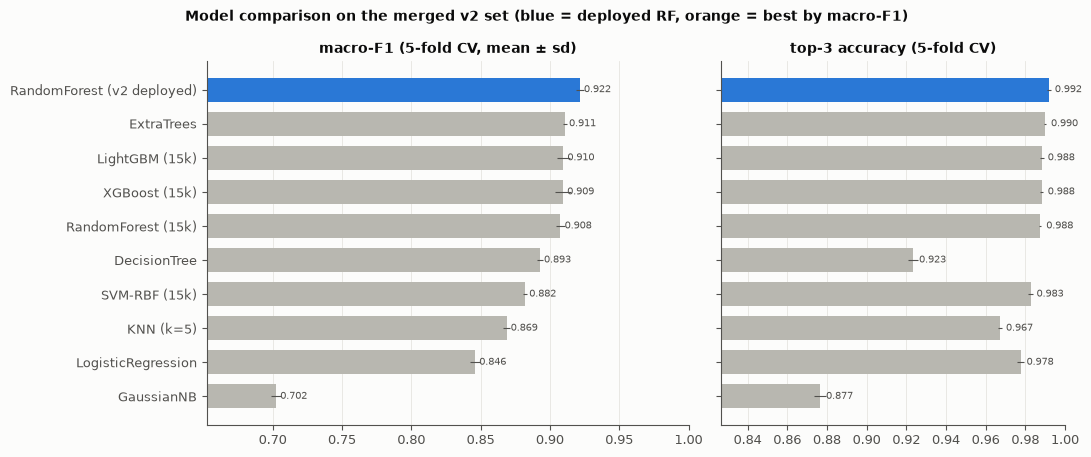

In [17]:
order = cmp_tab.index[::-1]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True, gridspec_kw={"width_ratios": [1.4, 1]})
for ax, key, title in [(axes[0], "f1", "macro-F1 (5-fold CV, mean ± sd)"), (axes[1], "top3", "top-3 accuracy (5-fold CV)")]:
    vals = [np.mean(cv_res[m][key]) for m in order]; err = [np.std(cv_res[m][key]) for m in order]
    colors = [PAL[0] if m == DEPLOYED else (PAL[1] if m == BEST else GREY) for m in order]
    ax.barh(order, vals, xerr=err, color=colors, height=0.7, error_kw={"lw": 0.8, "ecolor": "#52514e"})
    lo = min(vals) - 0.05
    ax.set_xlim(max(0, lo), 1.0); ax.set_title(title); ax.grid(axis="y", visible=False)
    for i, v in enumerate(vals):
        ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=7, color="#52514e")
fig.suptitle("Model comparison on the merged v2 set (blue = deployed RF, orange = best by macro-F1)", fontsize=10, fontweight="bold")
fig.tight_layout()
save(fig, "05_model_comparison.png", "Stratified 5-fold CV macro-F1 and top-3 accuracy of eleven classifiers on the merged v2 data.")

**Observation.**

* **Best model.** The deployed Random Forest is the best of the ten models on every metric: accuracy **94.33 % ± 0.12 %**, macro-F1 **92.15 % ± 0.29 %**, top-3 **99.18 % ± 0.09 %**. The fold-to-fold spread is small (≤ 0.3 points), so the ranking is stable.
* **Boosters at equal data.** On the same 15k training rows, Random Forest (93.46 %), LightGBM (93.48 %) and XGBoost (93.44 %) are statistically indistinguishable, while the boosters cost 30–40× more training time. The boosters offer no accuracy advantage on these data.
* **Simpler models.** Linear (87.0 %), distance-based (KNN 89.0 %, SVM 90.8 %) and naive-Bayes (71.6 %) models trail the forest.
* **Where the errors are.** The per-source columns locate the remaining error almost entirely in the multi-state rows: 71.5 % accuracy there, against 97.3 % on Tamil Nadu and 99.4 % on Kaggle.

### 3.1 Reproducing the application's own reported metric

**Method.** `model_service.py` scores the deployed forest on one stratified 80/20 split (`random_state=42`). We re-run that protocol to connect the cross-validated numbers above with the figure quoted in `docs/PROJECT.md` (0.9453 / 0.992).

In [18]:
idx_tr, idx_te = train_test_split(np.arange(len(Y)), test_size=0.2, random_state=42, stratify=Y)
rf_app = make_pipeline(prep(), rf_v2()).fit(X.iloc[idx_tr], Y[idx_tr])
P_rf = rf_app.predict_proba(X.iloc[idx_te]); pred_rf = rf_app.classes_[P_rf.argmax(1)]
R["app_protocol"] = {"split": "train_test_split(test_size=0.2, random_state=42, stratify=crop)",
                     "accuracy": r4(accuracy_score(Y[idx_te], pred_rf)),
                     "top3": r4(top_k_accuracy_score(Y[idx_te], P_rf, k=3, labels=rf_app.classes_)),
                     "macro_f1": r4(f1_score(Y[idx_te], pred_rf, average="macro")),
                     "project_md_claim": {"accuracy": 0.9453, "top3": 0.992}, "test_rows": int(len(idx_te))}
print(f"Accuracy: {100 * R['app_protocol']['accuracy']:.2f}%   Top-3: {100 * R['app_protocol']['top3']:.2f}%   "
      f"macro-F1: {100 * R['app_protocol']['macro_f1']:.2f}%   (PROJECT.md claims 94.53% / 99.2%)")
print(classification_report(Y[idx_te], pred_rf, target_names=le.classes_, digits=4))

Accuracy: 94.62%   Top-3: 99.21%   macro-F1: 92.32%   (PROJECT.md claims 94.53% / 99.2%)
                 precision    recall  f1-score   support

          apple     1.0000    1.0000    1.0000        20
       ashgourd     0.9124    0.9900    0.9496       200
          bajra     0.9247    0.9286    0.9266       238
         banana     0.8977    0.9029    0.9003       340
         barley     0.6667    0.1818    0.2857        11
       beetroot     1.0000    1.0000    1.0000       200
    bittergourd     0.7541    0.9200    0.8288       200
      blackgram     1.0000    1.0000    1.0000       220
    bottlegourd     0.9840    0.9250    0.9536       200
        brinjal     0.9950    1.0000    0.9975       200
        cabbage     1.0000    1.0000    1.0000       200
       capsicum     1.0000    0.9950    0.9975       200
         carrot     1.0000    1.0000    1.0000       200
         castor     0.9950    1.0000    0.9975       200
    cauliflower     1.0000    1.0000    1.0000       20

## 4. Ablation: what do soil, season and state add?

**Aim.** Measure, rather than assume, whether the categorical context that distinguishes v2 from v1 (soil, season, Indian state) improves recommendations.
**Method.** The deployed forest configuration is re-trained on the same five folds with the feature sets below. Accuracy is also broken down per source, because the multi-state source is the only one in which `state` varies.

In [19]:
ABL = {"numeric only": [], "+soil": ["soil"], "+season": ["season"], "+state": ["state"],
       "+soil+season": ["soil", "season"], "+soil+season+state (v2)": CAT}
abl_res, abl_oof = {}, {}
for name, cats in ABL.items():
    abl_res[name], abl_oof[name] = run_cv(rf_v2, cat=cats)
    r = abl_res[name]
    print(f"{name:26s} Accuracy {pct(r['acc'])}  folds {folds_pct(r['acc'])}  macro-F1 {pct(r['f1'])}  top-3 {pct(r['top3'])}", flush=True)
abl_tab = pd.DataFrame({name: {"accuracy": ms(r["acc"]), "macro_f1": ms(r["f1"]), "top3": ms(r["top3"]),
                               **{f"acc_{s}": round(float((abl_oof[name][SRC == s] == Y[SRC == s]).mean()), 4) for s in SRCS}}
                        for name, r in abl_res.items()}).T
R["ablation"] = {name: {"accuracy_mean": r4(np.mean(r["acc"])), "accuracy_std": r4(np.std(r["acc"])),
                        "macro_f1_mean": r4(np.mean(r["f1"])), "top3_mean": r4(np.mean(r["top3"])),
                        **{f"oof_accuracy_{s}": r4((abl_oof[name][SRC == s] == Y[SRC == s]).mean()) for s in SRCS}}
                 for name, r in abl_res.items()}
abl_tab

numeric only               Accuracy 87.16% ± 0.12%  folds [87.02, 87.09, 87.27, 87.34, 87.11] %  macro-F1 83.44% ± 0.11%  top-3 95.57% ± 0.17%


+soil                      Accuracy 89.10% ± 0.21%  folds [88.88, 88.90, 89.39, 89.29, 89.01] %  macro-F1 85.23% ± 0.15%  top-3 96.19% ± 0.24%


+season                    Accuracy 91.71% ± 0.16%  folds [91.61, 91.54, 91.60, 91.97, 91.80] %  macro-F1 88.44% ± 0.30%  top-3 98.31% ± 0.08%


+state                     Accuracy 87.47% ± 0.13%  folds [87.43, 87.31, 87.55, 87.67, 87.41] %  macro-F1 84.07% ± 0.24%  top-3 96.45% ± 0.11%


+soil+season               Accuracy 93.44% ± 0.21%  folds [93.25, 93.22, 93.81, 93.53, 93.40] %  macro-F1 90.53% ± 0.21%  top-3 98.68% ± 0.11%


+soil+season+state (v2)    Accuracy 94.33% ± 0.12%  folds [94.28, 94.18, 94.52, 94.39, 94.28] %  macro-F1 92.15% ± 0.29%  top-3 99.18% ± 0.09%


,accuracy,macro_f1,top3,acc_india,acc_tamilnadu,acc_kaggle
numeric only,0.8716 ± 0.0012,0.8344 ± 0.0011,0.9557 ± 0.0017,0.3222,0.9441,0.9909
+soil,0.8910 ± 0.0021,0.8523 ± 0.0015,0.9619 ± 0.0024,0.3322,0.9654,0.9927
+season,0.9171 ± 0.0016,0.8844 ± 0.0030,0.9831 ± 0.0008,0.5933,0.9596,0.9927
+state,0.8747 ± 0.0013,0.8407 ± 0.0024,0.9645 ± 0.0011,0.3493,0.9438,0.995
+soil+season,0.9344 ± 0.0021,0.9053 ± 0.0021,0.9868 ± 0.0011,0.6421,0.9732,0.9936
+soil+season+state (v2),0.9433 ± 0.0012,0.9215 ± 0.0029,0.9918 ± 0.0009,0.715,0.9734,0.9941


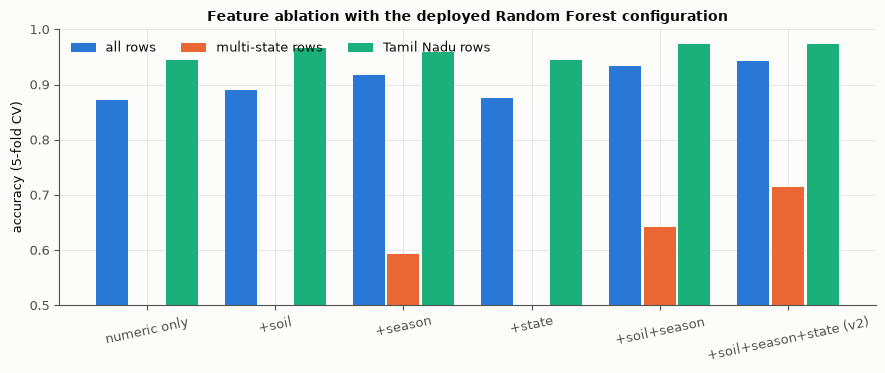

In [20]:
fig, ax = plt.subplots(figsize=(9, 3.8))
names = list(ABL); pos = np.arange(len(names))
series = [("all rows", None, PAL[0]), ("multi-state rows", "india", PAL[1]), ("Tamil Nadu rows", "tamilnadu", PAL[2])]
for i, (lab, s, c) in enumerate(series):
    vals = [np.mean(abl_res[n]["acc"]) if s is None else (abl_oof[n][SRC == s] == Y[SRC == s]).mean() for n in names]
    ax.bar(pos + (i - 1) * 0.27, vals, 0.25, color=c, label=lab)
ax.set_xticks(pos, names, rotation=12); ax.set_ylabel("accuracy (5-fold CV)")
ax.set_ylim(0.5, 1.0); ax.legend(frameon=False, ncol=3, loc="upper left")
ax.set_title("Feature ablation with the deployed Random Forest configuration")
fig.tight_layout()
save(fig, "06_ablation.png", "Accuracy of the deployed RF configuration with different categorical feature sets, overall and per source.")

**Observation.**

* **Season helps most.** Adding `season` gives the largest gain (+4.55 points over numeric-only, 87.16 % → 91.71 %).
* **Soil adds less, but complements season.** `soil` alone adds +1.94 points; soil and season together reach 93.44 %.
* **State: small overall, large where it varies.** Adding `state` alone adds only +0.31 points overall, and on top of soil+season it adds +0.89 points (to 94.33 %). That small overall gain hides a large local one: on the multi-state rows, where `state` actually varies, it raises accuracy from **64.2 % to 71.5 % (+7.3 points)**. State-awareness therefore helps exactly where it should.
* **The overall gain is small because** `state` is constant within the Tamil Nadu and Kaggle sources, which make up 88 % of the rows. Permutation importance (§6.1) gives the same picture.

## 5. Generalisation beyond the training distribution

**Aim.** Random K-fold CV only tests interpolation inside the same sources. A recommender is used on farms that were not in the training data, so we test transfer explicitly, following the argument for blocked / grouped cross-validation in [18, 19].

### 5.1 Leave-one-source-out (LOSO)

**Method.** Train on two sources, test on the third. A model cannot predict a crop it has never seen, so the test set is restricted to held-out rows whose crop occurs in the training sources; the share of rows kept is reported as *coverage*. Three variants: (i) *open set*: the deployed configuration trained on every crop of the two training sources; (ii) *numeric only*: the same without categorical features (`state`/`soil` values of the held-out source may be unseen); (iii) *closed set*: training restricted to the crops shared with the held-out source, so the model only has to choose among crops that are actually possible. Chance level is 1 / (number of shared crops).

In [21]:
def loso(held, cats, closed):
    tr = df[df.source != held]; te = df[(df.source == held) & df.crop.isin(set(tr.crop))]
    if closed:
        tr = tr[tr.crop.isin(set(te.crop))]
    m = make_pipeline(prep(cat=cats), rf_v2()).fit(tr[FEATURES], tr.crop)
    S = m.predict_proba(te[FEATURES]); pred = m.classes_[S.argmax(1)]
    labs = np.unique(te.crop)
    return {"n_test": len(te), "coverage_%": round(100 * len(te) / (df.source == held).sum(), 1),
            "shared_crops": len(labs), "chance": round(1 / len(labs), 4),
            "accuracy": accuracy_score(te.crop, pred), "macro_f1": f1_score(te.crop, pred, labels=labs, average="macro"),
            "top3": top_k_accuracy_score(te.crop, S, k=3, labels=m.classes_)}

rows = []
for held in SRCS:
    for variant, cats, closed in [("open set", CAT, False), ("numeric only", [], False), ("closed set", CAT, True)]:
        rows.append({"held_out": SRC_NAME[held], "variant": variant, **loso(held, cats, closed),
                     "in_distribution_acc": (OOF[DEPLOYED][SRC == held] == Y[SRC == held]).mean()})
        r = rows[-1]
        print(f"held out {SRC_NAME[held]:20s} {variant:13s} Accuracy {100 * r['accuracy']:6.2f}%  top-3 {100 * r['top3']:6.2f}%  "
              f"(in-distribution {100 * r['in_distribution_acc']:.2f}%, chance {100 * r['chance']:.2f}%, n={r['n_test']})", flush=True)
loso_tab = pd.DataFrame(rows).set_index(["held_out", "variant"])
R["loso"] = {f"{h}|{v}": {k: (r4(val) if isinstance(val, float) else int(val)) for k, val in r.items()}
             for (h, v), r in loso_tab.iterrows()}
loso_tab.round(4)

held out Multi-state (india)  open set      Accuracy  11.50%  top-3  22.05%  (in-distribution 71.50%, chance 5.56%, n=5419)


held out Multi-state (india)  numeric only  Accuracy   9.21%  top-3  13.60%  (in-distribution 71.50%, chance 5.56%, n=5419)


held out Multi-state (india)  closed set    Accuracy  13.67%  top-3  33.75%  (in-distribution 71.50%, chance 5.56%, n=5419)


held out Tamil Nadu           open set      Accuracy  12.89%  top-3  29.01%  (in-distribution 97.34%, chance 5.26%, n=19000)


held out Tamil Nadu           numeric only  Accuracy   0.43%  top-3  11.74%  (in-distribution 97.34%, chance 5.26%, n=19000)


held out Tamil Nadu           closed set    Accuracy  11.85%  top-3  39.30%  (in-distribution 97.34%, chance 5.26%, n=19000)


held out Kaggle               open set      Accuracy   7.00%  top-3  14.36%  (in-distribution 99.41%, chance 7.14%, n=1400)


held out Kaggle               numeric only  Accuracy   1.14%  top-3   3.86%  (in-distribution 99.41%, chance 7.14%, n=1400)


held out Kaggle               closed set    Accuracy  32.57%  top-3  54.36%  (in-distribution 99.41%, chance 7.14%, n=1400)


n_test  coverage_%  shared_crops  chance  \
held_out            variant                                                  
Multi-state (india) open set        5419        67.7            18  0.0556   
                    numeric only    5419        67.7            18  0.0556   
                    closed set      5419        67.7            18  0.0556   
Tamil Nadu          open set       19000        33.3            19  0.0526   
                    numeric only   19000        33.3            19  0.0526   
                    closed set     19000        33.3            19  0.0526   
Kaggle              open set        1400        63.6            14  0.0714   
                    numeric only    1400        63.6            14  0.0714   
                    closed set      1400        63.6            14  0.0714   

                                  accuracy  macro_f1    top3  \
held_out            variant                                    
Multi-state (india) open set        0.1150    0.0621  0.2205   
                    numeric only    0.0921    0.0234  0.1360   
                    closed set      0.1367    0.0716  0.3375   
Tamil Nadu          open set        0.1289    0.1119  0.2901   
                    numeric only    0.0043    0.0043  0.1174   
                    closed set      0.1185    0.0930  0.3930   
Kaggle              open set        0.0700    0.0353  0.1436   
                    numeric only    0.0114    0.0193  0.0386   
                    closed set      0.3257    0.2364  0.5436   

                                  in_distribution_acc  
held_out            variant                            
Multi-state (india) open set                   0.7150  
                    numeric only               0.7150  
                    closed set                 0.7150  
Tamil Nadu          open set                   0.9734  
                    numeric only               0.9734  
                    closed set                 0.9734  
Kaggle              open set                   0.9941  
                    numeric only               0.9941  
                    closed set                 0.9941

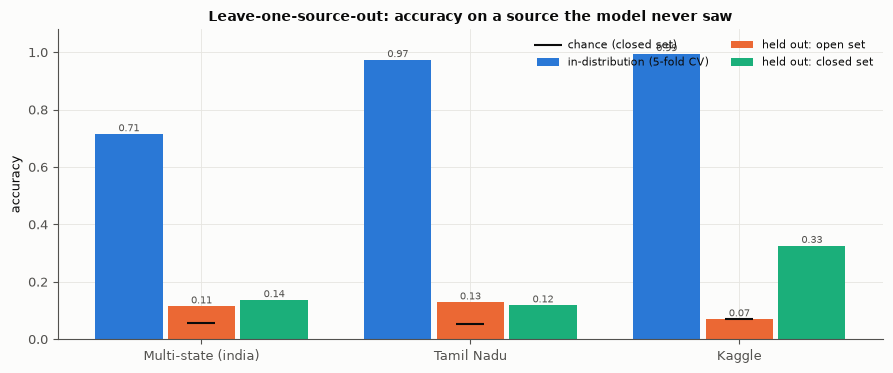

In [22]:
fig, ax = plt.subplots(figsize=(9, 3.8))
names = [SRC_NAME[s] for s in SRCS]; pos = np.arange(3)
bars = [("in-distribution (5-fold CV)", None, PAL[0]), ("held out: open set", "open set", PAL[1]),
        ("held out: closed set", "closed set", PAL[2])]
for i, (lab, v, c) in enumerate(bars):
    vals = [loso_tab.loc[(n, "open set"), "in_distribution_acc"] if v is None else loso_tab.loc[(n, v), "accuracy"] for n in names]
    ax.bar(pos + (i - 1) * 0.27, vals, 0.25, color=c, label=lab)
    for p, val in zip(pos, vals):
        ax.text(p + (i - 1) * 0.27, val + 0.01, f"{val:.2f}", ha="center", fontsize=7, color="#52514e")
ax.scatter(pos, [loso_tab.loc[(n, "open set"), "chance"] for n in names], marker="_", s=400, color="#0b0b0b", label="chance (closed set)", zorder=3)
ax.set_xticks(pos, names); ax.set_ylabel("accuracy"); ax.set_ylim(0, 1.08)
ax.legend(frameon=False, fontsize=8, ncol=2, loc="upper right")
ax.set_title("Leave-one-source-out: accuracy on a source the model never saw")
fig.tight_layout()
save(fig, "07_loso.png", "In-distribution CV accuracy versus leave-one-source-out accuracy (open and closed crop vocabulary) for each source.")

### 5.2 Leave-states-out inside the multi-state source

**Method.** The multi-state source is the only one with 16 states. Rows are grouped by state and evaluated with 4-fold `GroupKFold`, so every test state is absent from training (the `state` feature is dropped, since an unseen state cannot be encoded). This is compared with an ordinary stratified 4-fold split of the same rows, with and without `state`.

In [23]:
ind = df[df.source == "india"].reset_index(drop=True)
Xi, yi = ind[FEATURES], ind.crop.values
def cv_india(splits, cats):
    acc, f1 = [], []
    for a, b in splits:
        m = make_pipeline(prep(cat=cats), rf_v2()).fit(Xi.iloc[a], yi[a]); p = m.predict(Xi.iloc[b])
        acc.append(accuracy_score(yi[b], p)); f1.append(f1_score(yi[b], p, average="macro"))
    return acc, f1
strat = list(StratifiedKFold(4, shuffle=True, random_state=SEED).split(Xi, yi))
groups = list(GroupKFold(4).split(Xi, yi, groups=ind.state))
lso = {"random split, with state": cv_india(strat, CAT), "random split, no state": cv_india(strat, ["soil", "season"]),
       "unseen states (GroupKFold), no state": cv_india(groups, ["soil", "season"])}
for k, (a, f) in lso.items():
    print(f"{k:38s} Accuracy per fold {folds_pct(a)} -> {pct(a)}")
R["leave_states_out"] = {k: {"accuracy_mean": r4(np.mean(a)), "accuracy_std": r4(np.std(a)), "macro_f1_mean": r4(np.mean(f))}
                         for k, (a, f) in lso.items()}
pd.DataFrame({k: {"accuracy": ms(a), "macro_f1": ms(f)} for k, (a, f) in lso.items()}).T

random split, with state               Accuracy per fold [71.00, 70.50, 72.30, 70.95] % -> 71.19% ± 0.67%
random split, no state                 Accuracy per fold [66.85, 64.90, 65.45, 64.05] % -> 65.31% ± 1.02%
unseen states (GroupKFold), no state   Accuracy per fold [53.03, 59.50, 57.62, 53.25] % -> 55.85% ± 2.79%


,accuracy,macro_f1
"random split, with state",0.7119 ± 0.0067,0.5337 ± 0.0132
"random split, no state",0.6531 ± 0.0102,0.4544 ± 0.0070
"unseen states (GroupKFold), no state",0.5585 ± 0.0279,0.3127 ± 0.0368


**Observation.** Reported honestly, the v2 model **does not transfer between sources**.

* **Open set.** With one source held out, open-set accuracy falls from 71.5–99.4 % in distribution to **7.0–12.9 %**. In the Kaggle case (7.0 %) this is at chance (7.1 %).
* **Numeric features alone transfer worst** (0.4–9.2 %), which is the expected consequence of the incompatible `rainfall`/N scales documented in §2.3.
* **Closed set.** Restricting the model to crops that are actually possible helps only partly: Kaggle 32.6 % (top-3 54.4 %), Tamil Nadu 11.9 % (top-3 39.3 %).
* **Unseen states.** Within the multi-state source, predicting for states absent from training costs about 9.5 points relative to a random split without `state` (55.9 % ± 2.8 % vs 65.3 % ± 1.0 %), and 15.3 points relative to the deployed configuration with `state` (71.2 %).

The random-split numbers of §3 therefore describe interpolation inside the three sources, not performance on a new region. This is the main limitation of v2. It also changes what more data should mean. The three sources disagree with one another about the same crop (§2.3), and two of them behave like near-lookup tables (§2.1), so stacking further sets of this kind would not yield a model that transfers to a new region. This is the motivation for v3: real Government of India district–season–year crop statistics [30, 36], joined with measured climate and soil [27, 29] and evaluated with grouped (leave-district / leave-state / leave-years-out) validation [18, 19].

## 6. Diagnostics of the v2 model

All diagnostics use the application's own 80/20 split (§3.1), so that they describe the deployed model.

### 6.1 Permutation feature importance

**Method.** Each raw input column (one-hot groups are permuted as one column) is shuffled in a 5,000-row sample of the test split, 5 repeats, and the drop in accuracy is recorded. Unlike impurity importance, this is measured on held-out data and is not biased towards high-cardinality features.

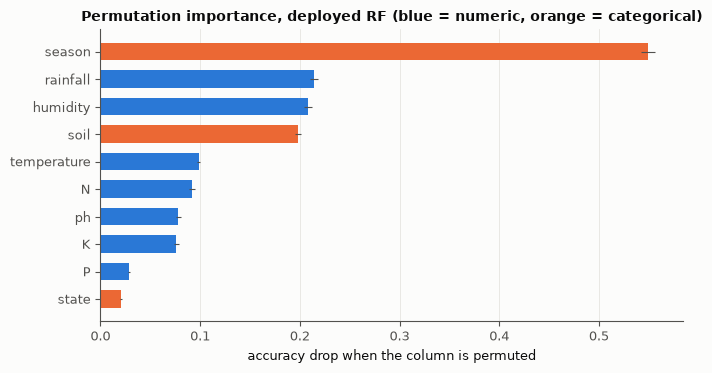

,mean_drop,std
season,0.5496,0.0069
rainfall,0.2144,0.0041
humidity,0.2078,0.0041
soil,0.1981,0.0033
temperature,0.0984,0.0014
N,0.0919,0.0033
ph,0.0782,0.0027
K,0.0761,0.0027
P,0.0286,0.0011
state,0.0203,0.0010


In [24]:
rng = np.random.RandomState(SEED)
samp = rng.choice(idx_te, 5000, replace=False)
pi = permutation_importance(rf_app, X.iloc[samp], Y[samp], n_repeats=5, random_state=SEED, scoring="accuracy")
imp = pd.DataFrame({"mean_drop": pi.importances_mean, "std": pi.importances_std}, index=FEATURES).sort_values("mean_drop")
R["importance"] = {f: {"accuracy_drop_mean": r4(r.mean_drop), "accuracy_drop_std": r4(r["std"])} for f, r in imp.iterrows()}
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(imp.index, imp.mean_drop, xerr=imp["std"], color=[PAL[1] if f in CAT else PAL[0] for f in imp.index], height=0.65,
        error_kw={"lw": 0.8, "ecolor": "#52514e"})
ax.set_xlabel("accuracy drop when the column is permuted"); ax.grid(axis="y", visible=False)
ax.set_title("Permutation importance, deployed RF (blue = numeric, orange = categorical)")
fig.tight_layout()
save(fig, "08_permutation_importance.png", "Permutation importance of each input column for the deployed RF on held-out data.")
imp[::-1].round(4)

### 6.2 Where the errors are: confusion among the most-confused crops

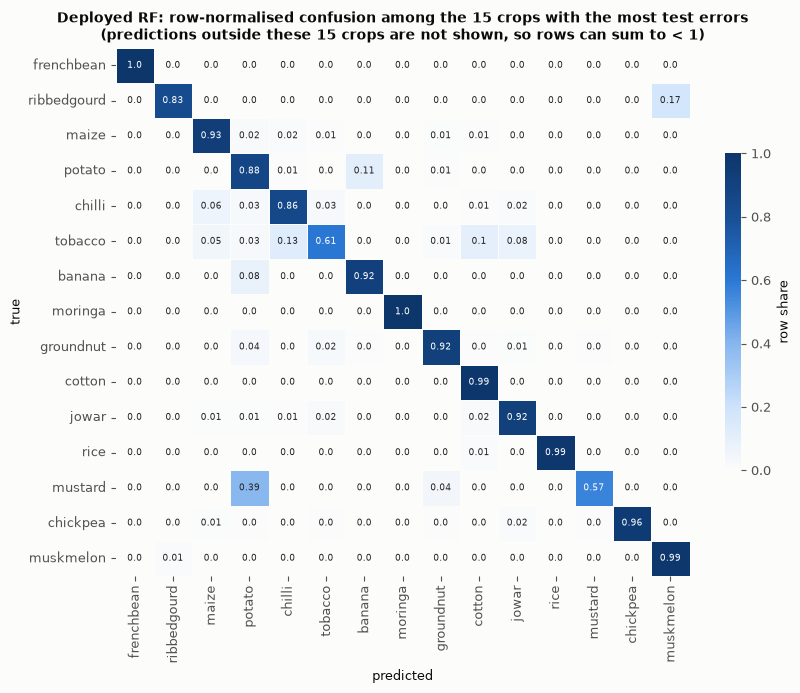

(frenchbean, cowpea)          66
(ribbedgourd, bittergourd)    35
(potato, banana)              33
(moringa, tinda)              28
(banana, potato)              28
(ribbedgourd, muskmelon)      28
(pumpkin, ashgourd)           19
(cotton, sugarcane)           17
Name: count, dtype: int64

In [25]:
err = pd.Series(le.classes_[Y[idx_te]][pred_rf != Y[idx_te]]).value_counts()
top = err.index[:15]
codes = le.transform(top)
mask = np.isin(Y[idx_te], codes)
cmx = confusion_matrix(Y[idx_te][mask], pred_rf[mask], labels=codes)
cmn = cmx / cmx.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cmn, ax=ax, cmap=BLUES, vmin=0, vmax=1, xticklabels=top, yticklabels=top, annot=np.round(cmn, 2),
            fmt="", annot_kws={"fontsize": 6.5}, linewidths=0.4, linecolor="#fcfcfb", cbar_kws={"shrink": 0.6, "label": "row share"})
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Deployed RF: row-normalised confusion among the 15 crops with the most test errors\n(predictions outside these 15 crops are not shown, so rows can sum to < 1)")
fig.tight_layout()
save(fig, "09_confusion_top_errors.png", "Row-normalised confusion matrix of the deployed RF for the 15 crops with the most test-set errors.")
pair = pd.Series(list(zip(le.classes_[Y[idx_te]], le.classes_[pred_rf])))[pred_rf != Y[idx_te]].value_counts().head(8)
R["confusion_top_pairs"] = [{"true": a, "predicted": b, "count": int(c)} for (a, b), c in pair.items()]
pair

### 6.3 Calibration of the predicted probabilities

**Aim.** The UI shows a confidence next to each recommendation, so the probabilities must mean what they say. Random forests are known to produce under-confident, compressed probabilities [20].
**Method.** Reliability diagram of the top-1 probability on the test split (15 equal-width bins), expected calibration error (ECE, the bin-weighted mean |accuracy − confidence|) [33] and the multiclass Brier score, for the deployed RF and the best model of §3.

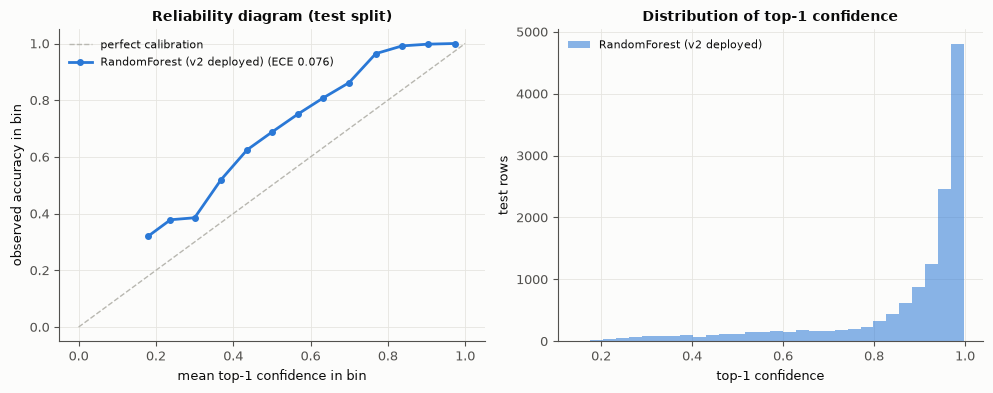

,ece,brier,mean_top1_confidence,accuracy
RandomForest (v2 deployed),0.0759,0.0885,0.8704,0.9462


In [26]:
def fit_best():
    make, scale, n = MODELS[BEST]
    tr_i = cap(idx_tr, n)
    return make_pipeline(prep(scale=scale), make()).fit(X.iloc[tr_i], Y[tr_i])
best_app = rf_app if BEST == DEPLOYED else fit_best()
P_best = scores_of(best_app, X.iloc[idx_te]); pred_best = best_app.classes_[P_best.argmax(1)]

def reliability(P, y, bins=15):
    conf, pred = P.max(1), P.argmax(1); hit = pred == y
    edges = np.linspace(0, 1, bins + 1); b = np.clip(np.digitize(conf, edges) - 1, 0, bins - 1)
    tab = pd.DataFrame({"b": b, "conf": conf, "hit": hit}).groupby("b").agg(conf=("conf", "mean"), acc=("hit", "mean"), n=("hit", "size"))
    ece = float((tab.n / len(y) * (tab.acc - tab.conf).abs()).sum())
    brier = float(((P - np.eye(P.shape[1])[y]) ** 2).sum(1).mean())
    return tab, ece, brier

calib = {}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot([0, 1], [0, 1], color=GREY, lw=1, ls="--", label="perfect calibration")
for (name, P), c in zip([(DEPLOYED, P_rf)] + ([(BEST, P_best)] if BEST != DEPLOYED else []), [PAL[0], PAL[1]]):
    if not hasattr(best_app, "predict_proba") and name == BEST:
        continue
    tab, ece, brier = reliability(P, Y[idx_te])
    calib[name] = {"ece": r4(ece), "brier": r4(brier), "mean_top1_confidence": r4(P.max(1).mean()),
                   "accuracy": r4((P.argmax(1) == Y[idx_te]).mean())}
    axes[0].plot(tab.conf, tab.acc, marker="o", ms=4, lw=2, color=c, label=f"{name} (ECE {ece:.3f})")
    axes[1].hist(P.max(1), bins=30, color=c, alpha=0.55, label=name)
axes[0].set_xlabel("mean top-1 confidence in bin"); axes[0].set_ylabel("observed accuracy in bin")
axes[0].set_title("Reliability diagram (test split)"); axes[0].legend(frameon=False, fontsize=8)
axes[1].set_xlabel("top-1 confidence"); axes[1].set_ylabel("test rows"); axes[1].set_title("Distribution of top-1 confidence")
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
save(fig, "10_calibration.png", "Reliability diagram and confidence histogram of the deployed RF (and the best CV model) on the application's test split.")
R["calibration"] = calib
pd.DataFrame(calib).T

**Observation.**

* **Permutation importance.** Permuting `season` costs 55.0 points of accuracy; it is the most important input. It is followed by rainfall (21.4), humidity (20.8) and soil (19.8). `state` ranks last overall (2.0), consistent with §4.
* **Systematic confusions.** The most frequent errors are agronomically plausible pairs: french bean → cowpea (66 test rows), ribbed gourd → bitter gourd (35), and potato ↔ banana (33 + 28).
* **Rare classes.** Weakest recall is on barley (0.18, 11 test rows) and mustard (0.38), both rare multi-state crops.
* **Calibration.** The forest is **under-confident**: mean top-1 confidence is 0.870 while accuracy is 0.946 (ECE 0.076, Brier 0.089). The reliability curve lies above the diagonal, the classic Random-Forest pattern [20]. The confidence the UI shows is therefore conservative.

### 6.4 McNemar test: v1-fixed versus v2

**Aim.** Test whether the difference between v1 and v2 is statistically significant on paired predictions, rather than comparing two accuracies computed on different data.
**Method.** v1-fixed is v1's best learner (default Random Forest, as in v1) trained as a proper multiclass model on the Kaggle rows of the v2 training split, using v1's seven numeric features. v2 is the deployed forest and the best CV model, trained on the full v2 training split. Both predict the *same* test rows. McNemar's test [32] uses only the discordant pairs: *b* = rows v1 gets right and v2 gets wrong, *c* = the reverse; we report the exact binomial p-value and the continuity-corrected χ² statistic. Two test sets are used: (a) the Kaggle rows of the test split, i.e. v1's home ground, where v2 must pick from 74 crops instead of 22; (b) the full v2 test split, i.e. the task v2 is built for.

In [27]:
kag_tr = idx_tr[SRC[idx_tr] == "kaggle"]
v1fix = RandomForestClassifier(random_state=1).fit(df.iloc[kag_tr][FEATS], Y[kag_tr])
pred_v1 = v1fix.predict(df.iloc[idx_te][FEATS])

def mcnemar(y, p_a, p_b):
    a_ok, b_ok = p_a == y, p_b == y
    b, c = int((a_ok & ~b_ok).sum()), int((~a_ok & b_ok).sum())
    chi2 = (abs(b - c) - 1) ** 2 / (b + c) if b + c else 0.0
    return {"n": int(len(y)), "acc_v1_fixed": r4(a_ok.mean()), "acc_v2": r4(b_ok.mean()),
            "b_v1_right_v2_wrong": b, "c_v1_wrong_v2_right": c, "chi2_cc": round(chi2, 3),
            "p_chi2": float(stats.chi2.sf(chi2, 1)), "p_exact": float(stats.binomtest(min(b, c), b + c, 0.5).pvalue) if b + c else 1.0}

on_kag = SRC[idx_te] == "kaggle"
mc = {}
for name, pv2 in [(DEPLOYED, pred_rf)] + ([(BEST, pred_best)] if BEST != DEPLOYED else []):
    mc[f"{name} | (a) Kaggle test rows"] = mcnemar(Y[idx_te][on_kag], pred_v1[on_kag], pv2[on_kag])
    mc[f"{name} | (b) full v2 test split"] = mcnemar(Y[idx_te], pred_v1, pv2)
R["mcnemar"] = mc
pd.DataFrame(mc).T

,n,acc_v1_fixed,acc_v2,b_v1_right_v2_wrong,c_v1_wrong_v2_right,chi2_cc,p_chi2,p_exact
RandomForest (v2 deployed) | (a) Kaggle test rows,440.0,0.9932,0.9955,0.0,1.0,0.000,1.0,1.0
RandomForest (v2 deployed) | (b) full v2 test split,13440.0,0.0441,0.9462,8.0,12132.0,12106.024,0.0,0.0


**Observation.**

* **(a) Kaggle test rows, v1's home ground.** Here v2 has to choose among 74 crops instead of 22. Even so, it is not worse than v1-fixed: 99.55 % vs 99.32 %, discordant pairs b = 0, c = 1, exact p = 1.0. The difference is not significant, so **v2 shows no regression on v1's task**.
* **(b) Full v2 test split.** v1-fixed reaches 4.41 %, because it cannot name 52 of the 74 crops. v2 reaches 94.62 % (b = 8, c = 12,132, p < 10⁻³⁰⁰).

The improvement is therefore one of *coverage* (more crops, more regions, context features) obtained without loss of accuracy on the original task, and not a higher number on the same task.

## 7. v3: real large-scale Indian data (reserved)

This section is reserved for the large real-world dataset (Government of India district–season–year crop statistics joined with NASA POWER climate and SoilGrids soil). When that dataset is available, the same protocol as §3 and §5 (model comparison and leave-years-out / leave-states-out tests) will be run here and the results stored under the `v3` key of `results.json`.

## 8. Summary: v1 → v2

In [28]:
best_v1_fixed = max(R["v1_fixed"], key=lambda m: R["v1_fixed"][m]["cv5_accuracy_mean"])
rf_m, best_m = R["models"][DEPLOYED], R["models"][BEST]
z0 = max(R["v1"], key=lambda m: R["v1"][m]["zero_fire_pct"])
zm = max(R["v1"], key=lambda m: R["v1"][m]["multi_fire_pct"])

def p_str(p):
    return "< 1e-300" if p == 0 else f"{p:.2g}"
lo_open = {s: R["loso"][f"{SRC_NAME[s]}|open set"]["accuracy"] for s in SRCS}
mc_b = R["mcnemar"][f"{DEPLOYED} | (b) full v2 test split"]
mc_a = R["mcnemar"][f"{DEPLOYED} | (a) Kaggle test rows"]
improvement = [
    {"aspect": "Training data", "v1": "2,200 rows (Kaggle only)", "v2": f"{len(df):,} rows (3 merged sources)", "note": "x30.5 rows"},
    {"aspect": "Crops covered", "v1": "22", "v2": str(K), "note": "Indian crops incl. millets, pulses, vegetables"},
    {"aspect": "Inputs", "v1": "7 numeric", "v2": "7 numeric + soil, season, state", "note": "§4 measures the value of each"},
    {"aspect": "Decoding", "v1": f"argmax over 22 binary heads: {R['v1'][z0]['zero_fire_pct']:.2f}% of rows with no head firing ({z0}), "
                                 f"{R['v1'][zm]['multi_fire_pct']:.2f}% with several ({zm}); GaussianNB exact-match "
                                 f"{100 * R['v1']['GaussianNB']['exact_match_accuracy']:.1f}% vs reported {100 * R['v1']['GaussianNB']['reported_accuracy']:.1f}%",
     "v2": "single multiclass model, one ranked answer per row", "note": "§1.1"},
    {"aspect": "Evaluation protocol", "v1": "one 75/25 split, accuracy only",
     "v2": "stratified 5-fold CV (mean ± sd), macro-F1, top-3, LOSO, leave-states-out, McNemar, calibration", "note": "§3–6"},
    {"aspect": "Headline accuracy (as reported)", "v1": "0.9800 (RF, 22 crops, 1 split)",
     "v2": f"{rf_m['accuracy_mean']:.4f} ± {rf_m['accuracy_std']:.4f} (RF, {K} crops, 5-fold)", "note": "not comparable tasks: see McNemar rows"},
    {"aspect": f"v1-fixed on v1's task (best: {best_v1_fixed})", "v1": f"{R['v1_fixed'][best_v1_fixed]['cv5_accuracy_mean']:.4f} (5-fold)",
     "v2": "—", "note": "the Kaggle task is near-trivially separable (§2.1)"},
    {"aspect": "Macro-F1 (v2 data, 5-fold)", "v1": "not reported", "v2": f"{rf_m['macro_f1_mean']:.4f} (deployed RF)",
     "note": "best of 10 models" if BEST == DEPLOYED else f"best: {BEST} {best_m['macro_f1_mean']:.4f}"},
    {"aspect": "Top-3 accuracy (v2 data, 5-fold)", "v1": "not reported", "v2": f"{rf_m['top3_mean']:.4f} (deployed RF)", "note": "UI shows 3 crops"},
    {"aspect": "Paired test, full v2 test split", "v1": f"{mc_b['acc_v1_fixed']:.4f}", "v2": f"{mc_b['acc_v2']:.4f}",
     "note": f"McNemar b={mc_b['b_v1_right_v2_wrong']}, c={mc_b['c_v1_wrong_v2_right']}, p={p_str(mc_b['p_exact'])}"},
    {"aspect": "Paired test, Kaggle test rows (v1's home ground)", "v1": f"{mc_a['acc_v1_fixed']:.4f}", "v2": f"{mc_a['acc_v2']:.4f}",
     "note": f"McNemar b={mc_a['b_v1_right_v2_wrong']}, c={mc_a['c_v1_wrong_v2_right']}, p={p_str(mc_a['p_exact'])}"},
    {"aspect": "Generalisation to an unseen source", "v1": "not tested",
     "v2": ", ".join(f"{SRC_NAME[s]} {lo_open[s]:.2f}" for s in SRCS), "note": "LOSO open-set accuracy (§5.1): v2 does not transfer across sources"},
    {"aspect": "Generalisation to unseen states (multi-state rows)", "v1": "not tested",
     "v2": f"{R['leave_states_out']['unseen states (GroupKFold), no state']['accuracy_mean']:.4f} vs {R['leave_states_out']['random split, no state']['accuracy_mean']:.4f} random split",
     "note": "GroupKFold by state (§5.2)"},
    {"aspect": "Probability calibration", "v1": "not measured", "v2": f"ECE {R['calibration'][DEPLOYED]['ece']:.3f} (deployed RF)", "note": "§6.3"},
]
R["improvement"] = improvement
for row in improvement:
    print(f"{row['aspect']}\n    v1: {row['v1']}\n    v2: {row['v2']}" + (f"\n    note: {row['note']}" if row["note"] else ""))

Training data
    v1: 2,200 rows (Kaggle only)
    v2: 67,200 rows (3 merged sources)
    note: x30.5 rows
Crops covered
    v1: 22
    v2: 74
    note: Indian crops incl. millets, pulses, vegetables
Inputs
    v1: 7 numeric
    v2: 7 numeric + soil, season, state
    note: §4 measures the value of each
Decoding
    v1: argmax over 22 binary heads: 3.09% of rows with no head firing (DecisionTree), 13.09% with several (GaussianNB); GaussianNB exact-match 86.9% vs reported 97.1%
    v2: single multiclass model, one ranked answer per row
    note: §1.1
Evaluation protocol
    v1: one 75/25 split, accuracy only
    v2: stratified 5-fold CV (mean ± sd), macro-F1, top-3, LOSO, leave-states-out, McNemar, calibration
    note: §3–6
Headline accuracy (as reported)
    v1: 0.9800 (RF, 22 crops, 1 split)
    v2: 0.9433 ± 0.0012 (RF, 74 crops, 5-fold)
    note: not comparable tasks: see McNemar rows
v1-fixed on v1's task (best: RandomForest)
    v1: 0.9950 (5-fold)
    v2: —
    note: the Kaggle t

In [29]:
R["meta"].update({"generated_by": "notebooks/AgroMind_v2_Research.ipynb", "date": time.strftime("%Y-%m-%d"),
                  "python": platform.python_version(), "sklearn": sklearn.__version__, "xgboost": xgb.__version__,
                  "lightgbm": lgb.__version__, "seed": SEED, "rows": int(len(df)), "crops": int(K),
                  "runtime_seconds": round(time.time() - T0, 1)})
R["_doc"] = {
    "v1": "v1 reproduced exactly (Kaggle, MultiOutputClassifier, argmax decode, 75/25 split rs=0). zero_fire_pct / multi_fire_pct = % of 550 test rows where no / >1 one-vs-rest head fires; pred_class0_pct = % predicted as class 0 (apple).",
    "v1_fixed": "same estimators as plain multiclass models: same split, and StratifiedKFold(5) on the full Kaggle set.",
    "dataset": "audit of the merged v2 set from backend/app/data_loader.load_dataset().",
    "models": "StratifiedKFold(5, shuffle, rs=42) on merged v2 data, features = 7 numerics + one-hot soil/season/state. *_mean/*_std over folds. train_rows_cap = training-fold subsample size (null = full fold). oof_accuracy_<source> = out-of-fold accuracy on that source's rows.",
    "app_protocol": "the backend's own 80/20 split re-run for the deployed RF.",
    "ablation": "deployed RF config, same folds, different categorical feature sets.",
    "loso": "key 'held_out|variant'. Train on two sources, test on the third restricted to crops seen in training. open set = all train crops; numeric only = no categorical features; closed set = training restricted to shared crops.",
    "leave_states_out": "multi-state source only, GroupKFold(4) by state vs StratifiedKFold(4).",
    "importance": "permutation importance (accuracy drop), deployed RF, 5,000 test rows, 5 repeats.",
    "calibration": "top-1 reliability on the app test split, 15 bins. ece = expected calibration error; brier = multiclass Brier score.",
    "mcnemar": "paired v1-fixed (RF on Kaggle rows, 7 numerics) vs v2 on the same test rows; b = v1 right & v2 wrong, c = v1 wrong & v2 right; p_exact = exact binomial test.",
    "improvement": "v1 -> v2 summary table (array of rows).",
    "figures": "PNG files relative to docs/research/.",
}
prev = json.loads((OUT / "results.json").read_text()) if (OUT / "results.json").exists() else {}
if "v3" in prev:  # written by AgroMind_v3_LargeScale.ipynb; keep it
    R["v3"] = prev["v3"]
    R["figures"] += [f for f in prev.get("figures", []) if "_v3_" in f["file"]]
(OUT / "results.json").write_text(json.dumps(R, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print("wrote", OUT / "results.json", "and", len(R["figures"]), "figures to", FIG)
print(f"total runtime {time.time() - T0:.0f}s")

wrote /Users/originkit/.config/baton/worktrees/agromind-334992/claude-1/docs/research/results.json and 10 figures to /Users/originkit/.config/baton/worktrees/agromind-334992/claude-1/docs/research/figures
total runtime 1644s
